In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [44]:
train = pd.read_csv("cve_cisa_epss_enriched_dataset.csv")
print("Ukuran Dataset: ", train.shape)

Ukuran Dataset:  (374917, 17)


In [45]:
# Memeriksa 5 baris pertama
train.head()

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
0,CVE-1999-0095,HIGH,10.0,10.0,10.0,0.16317,0.96889,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-10-01 04:00:00
1,CVE-1999-0082,HIGH,10.0,10.0,10.0,0.08281,0.94791,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1988-11-11 05:00:00
2,CVE-1999-1471,HIGH,7.2,3.9,10.0,0.00503,0.41171,False,LOCAL,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-01-01 05:00:00
3,CVE-1999-1122,MEDIUM,4.6,3.9,6.4,0.00383,0.30219,False,LOCAL,LOW,NaN,NaN,NaN,PARTIAL,PARTIAL,PARTIAL,1989-07-26 04:00:00
4,CVE-1999-1467,HIGH,10.0,10.0,10.0,0.10249,0.95581,False,NETWORK,LOW,NaN,NaN,NaN,COMPLETE,COMPLETE,COMPLETE,1989-10-26 04:00:00


In [46]:
# Memeriksa tipe data
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 374917 entries, 0 to 374916
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   cve_id                  374917 non-null  str    
 1   base_severity           374917 non-null  str    
 2   base_score              374917 non-null  float64
 3   exploitability_score    374917 non-null  float64
 4   impact_score            374917 non-null  float64
 5   epss_score              374646 non-null  float64
 6   epss_perc               374646 non-null  float64
 7   cisa_kev                374917 non-null  bool   
 8   attack_vector           374917 non-null  str    
 9   attack_complexity       374917 non-null  str    
 10  privileges_required     302512 non-null  str    
 11  user_interaction        302512 non-null  str    
 12  scope                   302512 non-null  str    
 13  confidentiality_impact  374917 non-null  str    
 14  integrity_impact        374917 

In [47]:
train.describe(include="all")

,cve_id,base_severity,base_score,exploitability_score,impact_score,epss_score,epss_perc,cisa_kev,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact,published_date
count,374917,374917,374917.000000,374917.000000,374917.000000,374646.000000,374646.000000,374917,374917,374917,302512,302512,302512,374917,374917,374917,374917
unique,374917,5,NaN,NaN,NaN,NaN,NaN,1,4,3,3,2,2,5,5,5,346510
top,CVE-1999-0095,MEDIUM,NaN,NaN,NaN,NaN,NaN,False,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH,2004-12-31 05:00:00.000
freq,1,170990,NaN,NaN,NaN,NaN,NaN,374917,283041,315686,168647,208089,240979,153489,129956,149772,1098
mean,NaN,NaN,6.804152,3.728966,4.464240,0.027521,0.507326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,1.798358,2.587553,1.926676,0.090306,0.287467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,0.000000,0.100000,0.000000,0.000490,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,5.400000,1.800000,2.900000,0.003450,0.259410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,7.000000,2.800000,3.700000,0.006840,0.511440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,7.800000,3.900000,5.900000,0.016350,0.756130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
# Memeriksa missing values
train.isnull().sum()

cve_id                        0
base_severity                 0
base_score                    0
exploitability_score          0
impact_score                  0
epss_score                  271
epss_perc                   271
cisa_kev                      0
attack_vector                 0
attack_complexity             0
privileges_required       72405
user_interaction          72405
scope                     72405
confidentiality_impact        0
integrity_impact              0
availability_impact           0
published_date                0
dtype: int64

In [49]:
# Memeriksa duplikat
train.duplicated().sum()

np.int64(0)

In [50]:
# Distribusi tingkat keparahan
train["base_severity"].value_counts(dropna=False)


base_severity
MEDIUM      170990
HIGH        150664
CRITICAL     36970
LOW          16246
NONE            47
Name: count, dtype: int64

In [51]:
train_clean = train[train["base_severity"] != "NONE"].copy()
train_clean["base_severity"].value_counts(dropna=False)

base_severity
MEDIUM      170990
HIGH        150664
CRITICAL     36970
LOW          16246
Name: count, dtype: int64

In [52]:
train["cisa_kev"].value_counts(dropna=False)

cisa_kev
False    374917
Name: count, dtype: int64

In [53]:
# Menghitung presentase nilai kosong dalam kolom
missing_percent = (train.isnull().sum() / len(train)) * 100

missing_percent[missing_percent > 0].sort_values(ascending=False)

privileges_required    19.312274
scope                  19.312274
user_interaction       19.312274
epss_score              0.072283
epss_perc               0.072283
dtype: float64

In [54]:
colms = ["user_interaction", "privileges_required", "scope"]

# HItung berapa baris yang kosong pada ketiga kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-3 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-3 kolom:  72405
Kosong pada minmal satu kolom:  72405


In [55]:
year = pd.to_datetime(train["published_date"], errors="coerce").dt.year
missing_by_year = train.groupby(year).agg(
    jumlah_baris = ("cve_id", "size"),
    jumlah_missing = ("user_interaction", lambda s: s.isnull().sum())
)

missing_by_year["persen_missing"] = (
    missing_by_year["jumlah_missing"] / missing_by_year["jumlah_baris"] * 100
)

print(missing_by_year)
# Memeriksa apakah ada missing value yang lebih dari tahun 2002
missing_by_year[missing_by_year.index > 2002]

                jumlah_baris  jumlah_missing  persen_missing
published_date                                              
1988.0                     2               2      100.000000
1989.0                     3               3      100.000000
1990.0                    11              10       90.909091
1991.0                    15              15      100.000000
1992.0                    13              13      100.000000
1993.0                    13              13      100.000000
1994.0                    25              25      100.000000
1995.0                    25              24       96.000000
1996.0                    74              72       97.297297
1997.0                   252             242       96.031746
1998.0                   246             236       95.934959
1999.0                   894             885       98.993289
2000.0                  1019            1009       99.018646
2001.0                  1675            1637       97.731343
2002.0                  

,jumlah_baris,jumlah_missing,persen_missing
published_date,,,


In [56]:
colms = ["epss_perc", "epss_score"]

# HItung berapa baris yang kosong pada kedua kolom
all_missing = train[colms].isnull().all(axis=1).sum()
# Hitng baris kosong pada setidaknya 1 kolom
any_missing = train[colms].isnull().any(axis=1).sum()

print("Kosong pada ke-2 kolom: ", all_missing)
print("Kosong pada minmal satu kolom: ", any_missing)

Kosong pada ke-2 kolom:  271
Kosong pada minmal satu kolom:  271


In [57]:
colms = ["epss_perc", "epss_score", "user_interaction", "privileges_required", "scope"]
print("Jumlah data sebelum di bersihkan: ", len(train))
train_clean = train_clean.dropna(subset=colms).copy()
print("Jumlah data sesudah di bersihkan: ", len(train_clean))
train_clean.isnull().sum()

Jumlah data sebelum di bersihkan:  374917
Jumlah data sesudah di bersihkan:  302194


cve_id                    0
base_severity             0
base_score                0
exploitability_score      0
impact_score              0
epss_score                0
epss_perc                 0
cisa_kev                  0
attack_vector             0
attack_complexity         0
privileges_required       0
user_interaction          0
scope                     0
confidentiality_impact    0
integrity_impact          0
availability_impact       0
published_date            0
dtype: int64

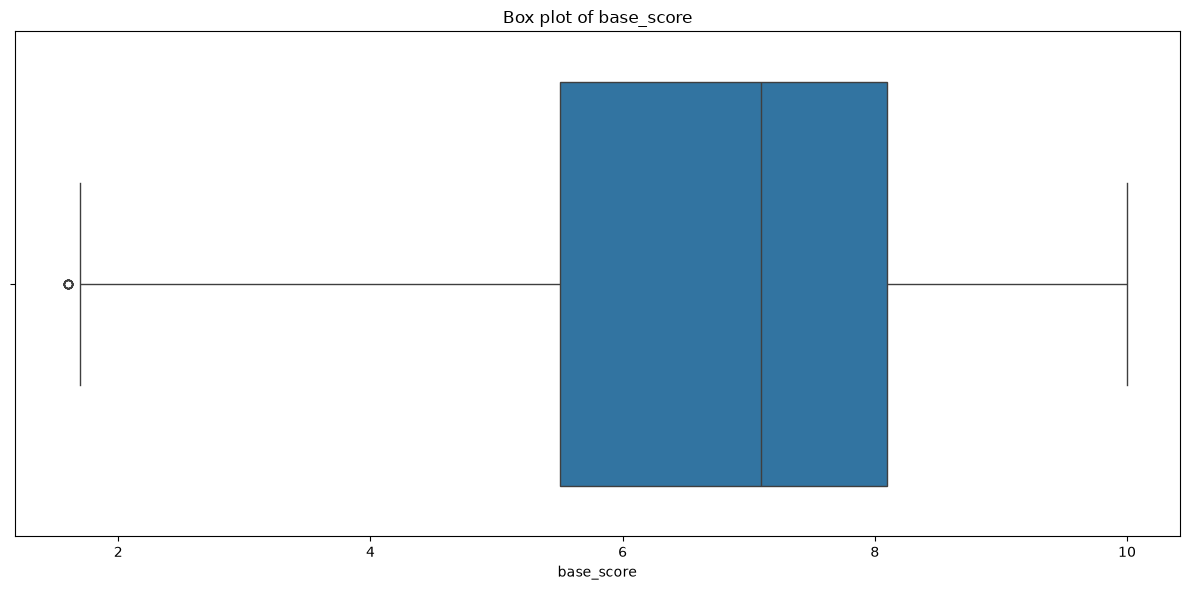

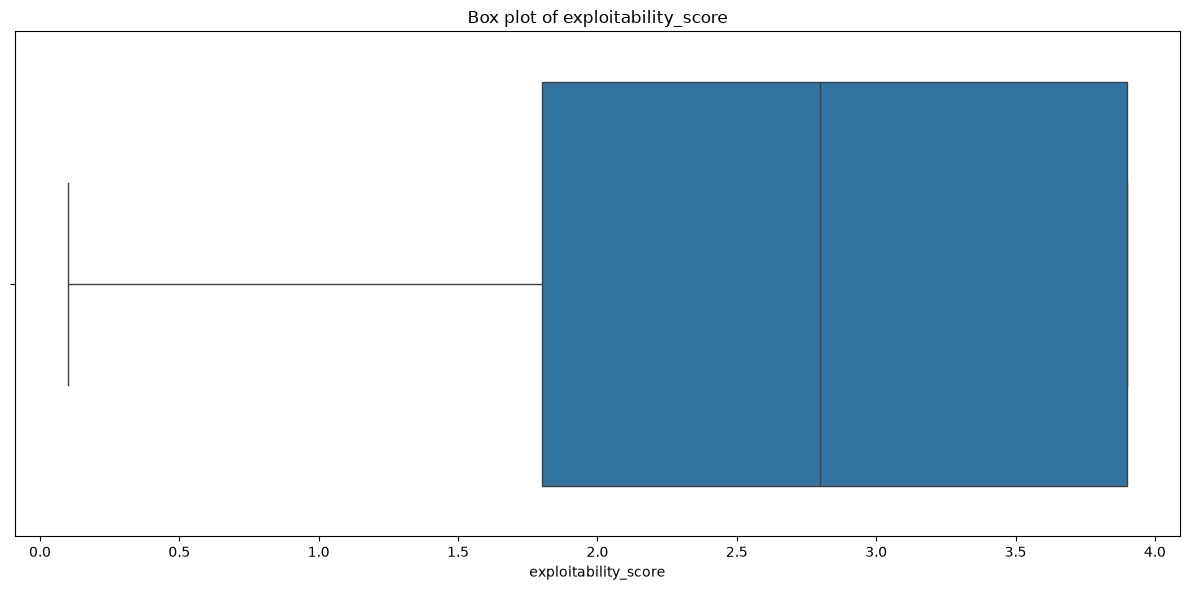

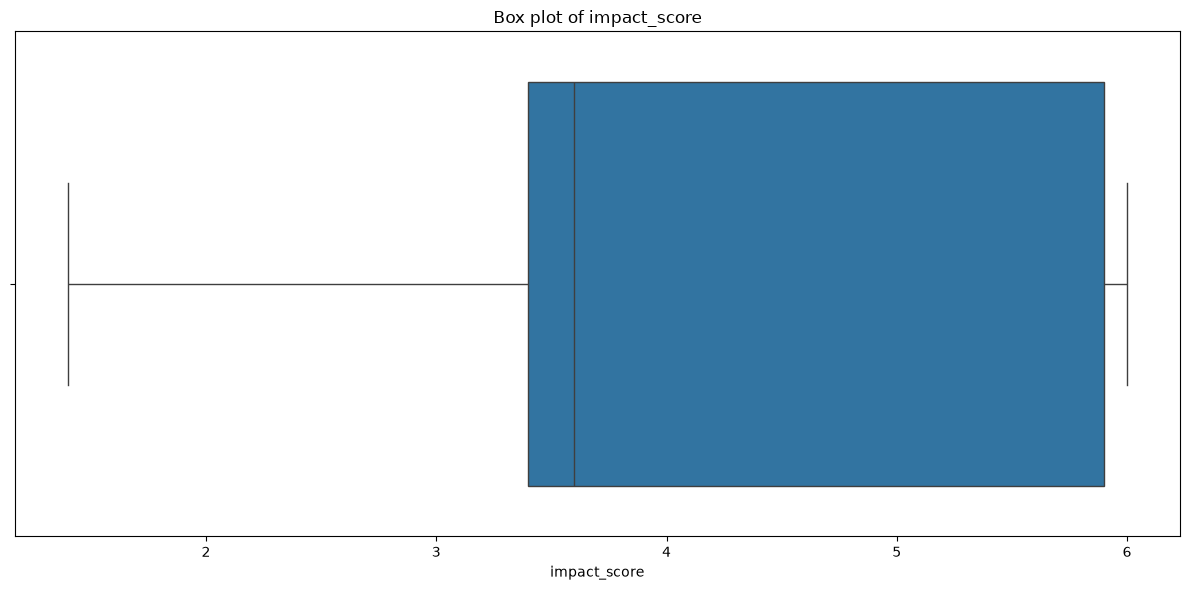

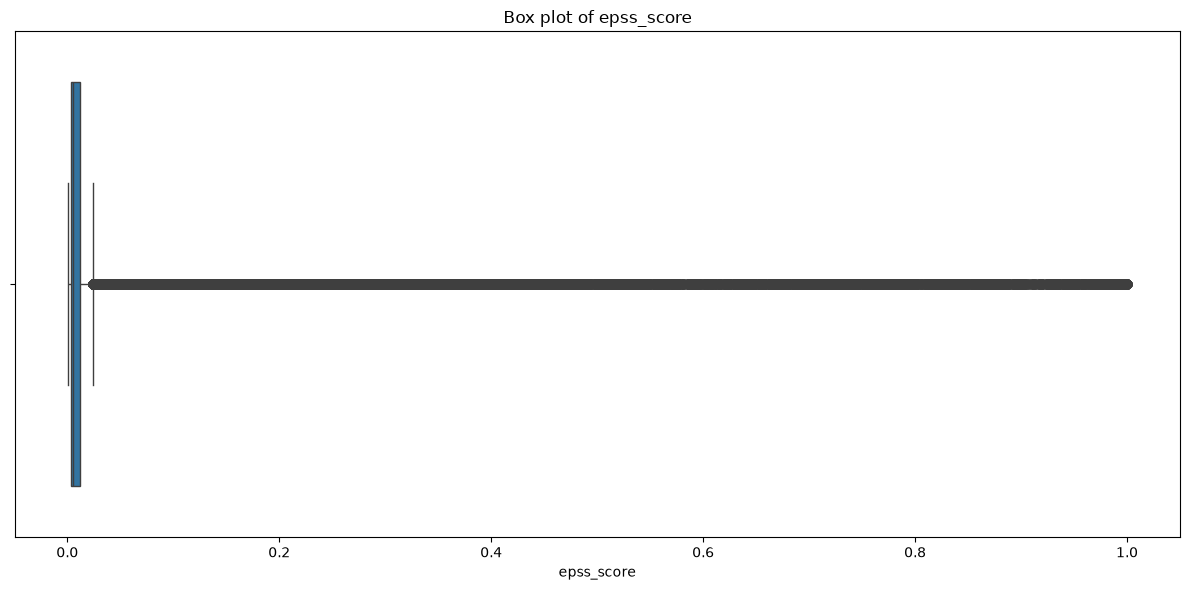

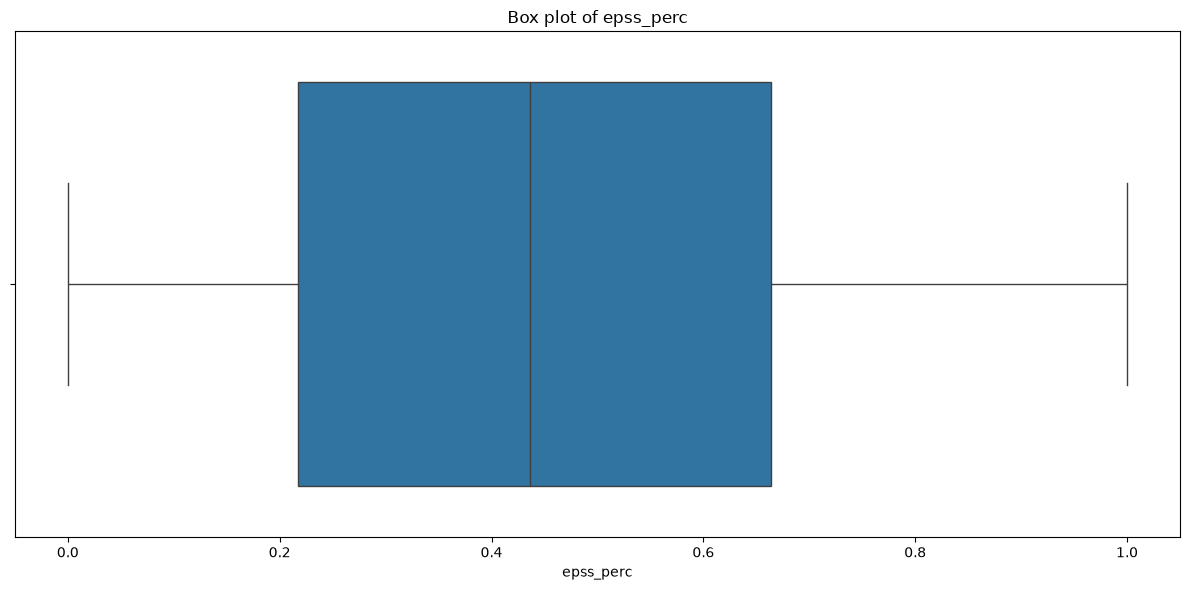

In [58]:
numeric_features = train_clean.select_dtypes(include="number").columns
for feature in numeric_features:
    plt.figure(figsize=(12,6))
    sns.boxplot(x=train_clean[feature])
    plt.title(f"Box plot of {feature}")
    plt.tight_layout()
    plt.show()

In [59]:
# Memeriksa outlier
Q1 = train_clean[numeric_features].quantile(0.25)
Q3 = train_clean[numeric_features].quantile(0.75)
IQR = Q3 - Q1

for feature in numeric_features:
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = (
        (train_clean[feature] < lower_bound[feature]) |
        (train_clean[feature] > upper_bound[feature])
    )

    print(f"\nKolom: {feature}")
    print(f"Jumlah baris outlier: {outliers.sum()}")



Kolom: base_score
Jumlah baris outlier: 9

Kolom: exploitability_score
Jumlah baris outlier: 0

Kolom: impact_score
Jumlah baris outlier: 0

Kolom: epss_score
Jumlah baris outlier: 33455

Kolom: epss_perc
Jumlah baris outlier: 0


In [60]:
kolom = ["cve_id",
        "base_score",
        "exploitability_score",
        "impact_score",
        "epss_score",
        "epss_perc",
        "cisa_kev",
        "published_date"
        ]
df = train_clean.drop(columns=kolom)
df.info()
df.head()


<class 'pandas.DataFrame'>
Index: 302194 entries, 6 to 374646
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   base_severity           302194 non-null  str  
 1   attack_vector           302194 non-null  str  
 2   attack_complexity       302194 non-null  str  
 3   privileges_required     302194 non-null  str  
 4   user_interaction        302194 non-null  str  
 5   scope                   302194 non-null  str  
 6   confidentiality_impact  302194 non-null  str  
 7   integrity_impact        302194 non-null  str  
 8   availability_impact     302194 non-null  str  
dtypes: str(9)
memory usage: 23.1 MB


,base_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact
6,HIGH,LOCAL,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
90,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
128,HIGH,LOCAL,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH
168,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
194,HIGH,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,NONE,NONE


In [61]:
df.isnull().sum()

base_severity             0
attack_vector             0
attack_complexity         0
privileges_required       0
user_interaction          0
scope                     0
confidentiality_impact    0
integrity_impact          0
availability_impact       0
dtype: int64

In [62]:
# Memisahkan fitur (X) dan target (y)*
X = df.drop(columns=["base_severity"])
x = pd.get_dummies(X)
y = df["base_severity"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)

# menghitung jumlah data*
print("Jumlah data: ",len(x))
# Menghitung jumlah data pada x_train*
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test*
print("Jumlah data test: ",len(x_test))

Jumlah data:  302194
Jumlah data latih:  241755
Jumlah data test:  60439
